# Decision Tree Classifier using Entropy

Decision tree learning is the construction of a decision tree from class-labeled training tuples. A decision tree is a flow-chart-like structure, where each internal (non-leaf) node denotes a test on an attribute, each branch represents the outcome of a test, and each leaf (or terminal) node holds a class label. The topmost node in a tree is the root node.

Information gain based on Entropy is one measure to decide which attribute has to be used for splitting the node.

Let there be $J$  classes.

Let $ p_i $  be the probabilities of items with class label $i$.


Entropy is defined as $$ H(T) = I_E(p_1, p_2, \ldots, p_J) =  \sum_{i=1}^J (-1) p_i \log_2 p_i $$

Information gain is defined as $$ IG(T,a) = H(T) - H(T \vert a) $$

The Zoo dataset (https://www.kaggle.com/uciml/zoo-animal-classification)

This dataset consists of 101 animals from a zoo.

There are 16 features or attributes with various traits to describe the animals: animal_name, hair, feathers, eggs, milk, airborne, aquatic, predator, toothed, backbone,     breathes, venomous, fins, legs, tail, domestic, catsize.

The 7 Class Types are: Mammal, Bird, Reptile, Fish, Amphibian, Bug and Invertebrate

The purpose for this dataset is to be able to predict the classification of the animals, based upon the attributes.

## 1. Import the dataset and verify

In [1]:
# Import the dataset ( Zoo dataset downloaded from Kaggle)

import pandas as pd

dataset = pd.read_csv('zoo.csv')

dataset.shape

(101, 18)

In [2]:
# view first few rows of the dataset

dataset.head()

# Class Number	Count	Class Name
# 1	41	Mammal
# 2	20	Bird
# 3	5	Reptile
# 4	13	Fish
# 5	4	Amphibian
# 6	8	Bug
# 7	10	Invertebrate

,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


## 2. Pre-processing

In [3]:
# Drop the first column which are the animal names

dataset=dataset.drop('animal_name',axis=1) # column

# view first few rows of the dataset again

dataset.head()

,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [4]:
# Split the dataset into training and testing set
# Split data into training and testing sets

X = dataset.iloc[:, :-1] # extract all rows, all column except for the last column.
y = dataset.iloc[:,-1]  # extract all rows, only the last column (the class label)

print(X.shape)
print(y.shape)

from sklearn.model_selection import train_test_split

(X_train, X_test, y_train, y_test) = train_test_split(X, y, test_size= 0.25, stratify = y, random_state=42)


print('Training Features :', X_train.shape)
print('Training Labels :', y_train.shape)
print('Testing Features :', X_test.shape)
print('Testing Labels :', y_test.shape)


(101, 16)
(101,)
Training Features : (75, 16)
Training Labels : (75,)
Testing Features : (26, 16)
Testing Labels : (26,)


## 3. Build and train the model

In [5]:
# Import the classifier from library

from sklearn.tree import DecisionTreeClassifier

# Train the classifier using Entropy

tree = DecisionTreeClassifier(criterion = 'entropy', random_state=42)

tree.fit(X_train, y_train) # for training

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [6]:
# Entropy and information gain, computed by hand for the ROOT split chosen by the tree,
# to check them against what sklearn's criterion='entropy' does internally.
import numpy as np

def entropy(labels):
    p = np.bincount(labels) / len(labels)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()          # H(T) = - sum p_i log2 p_i

root_feature = tree.tree_.feature[0]
root_threshold = tree.tree_.threshold[0]
left = (X_train.iloc[:, root_feature] <= root_threshold).values

H_T = entropy(y_train.values)
H_T_given_a = (left.mean() * entropy(y_train.values[left])
               + (~left).mean() * entropy(y_train.values[~left]))   # weighted child entropy
print('Root split: %s <= %.2f' % (X_train.columns[root_feature], root_threshold))
print('H(T)            = %.4f  (sklearn root impurity: %.4f)' % (H_T, tree.tree_.impurity[0]))
print('H(T | a)        = %.4f' % H_T_given_a)
print('IG(T, a)        = %.4f' % (H_T - H_T_given_a))

Root split: milk <= 0.50
H(T)            = 2.4029  (sklearn root impurity: 2.4029)
H(T | a)        = 1.4319
IG(T, a)        = 0.9710


## 4. Make predictions

In [7]:
# Predict the values for testing set

y_predict = tree.predict(X_test)

In [8]:
print(y_predict)

[1 2 7 2 4 1 1 2 4 1 3 6 1 7 5 1 1 2 6 1 1 1 4 7 2 1]


## 5. Performance Measures

In [9]:
# Accuracy of the classifier

from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, y_predict)
print(acc * 100 , "%")

100.0 %


In [10]:
# build the confusion matrix

from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, y_predict)
print('Confusion Matrix :')
print(conf_matrix)

Confusion Matrix :
[[11  0  0  0  0  0  0]
 [ 0  5  0  0  0  0  0]
 [ 0  0  1  0  0  0  0]
 [ 0  0  0  3  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  2  0]
 [ 0  0  0  0  0  0  3]]


In [11]:
# Classification Report - precision, recall

from sklearn.metrics import classification_report

print('Classification Report: ')
print(classification_report(y_test, y_predict))

# Precision is the positive predictive value -- no: of observations correctly labeled
# as belonging to positive class to total no: of observations  of postive class

# Recall -- number of true positives divided by the total no: of observations of positive class

# F1 score = 2 * (precision * recall) / (precision + recall)

Classification Report: 
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        11
           2       1.00      1.00      1.00         5
           3       1.00      1.00      1.00         1
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3

    accuracy                           1.00        26
   macro avg       1.00      1.00      1.00        26
weighted avg       1.00      1.00      1.00        26



## 6. Visualizing the tree

In [12]:
dataset.head()

,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [13]:
# extract the column or feature names and store as a list

feature_names = list(dataset.columns.values)

feature_names = feature_names[:-1]
print(feature_names)

['hair', 'feathers', 'eggs', 'milk', 'airborne', 'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous', 'fins', 'legs', 'tail', 'domestic', 'catsize']


In [14]:
# class names in the order of the class numbers 1..7 used in the dataset.
# export_graphviz / plot_tree expect them in sorted tree.classes_ order (1..7),
# NOT in the order in which unique() first meets them.
class_names = ['Mammal', 'Bird', 'Reptile', 'Fish', 'Amphibian', 'Bug', 'Invertebrate']
# one-one mapping between the int value used in the dataset and the class name
dictionary = dict(zip(tree.classes_, class_names))
print(dictionary)
# 1	41	Mammal
# 2	20	Bird
# 3	5	Reptile
# 4	13	Fish
# 5	4	Amphibian
# 6	8	Bug
# 7	10	Invertebrate

{np.int64(1): 'Mammal', np.int64(2): 'Bird', np.int64(3): 'Reptile', np.int64(4): 'Fish', np.int64(5): 'Amphibian', np.int64(6): 'Bug', np.int64(7): 'Invertebrate'}


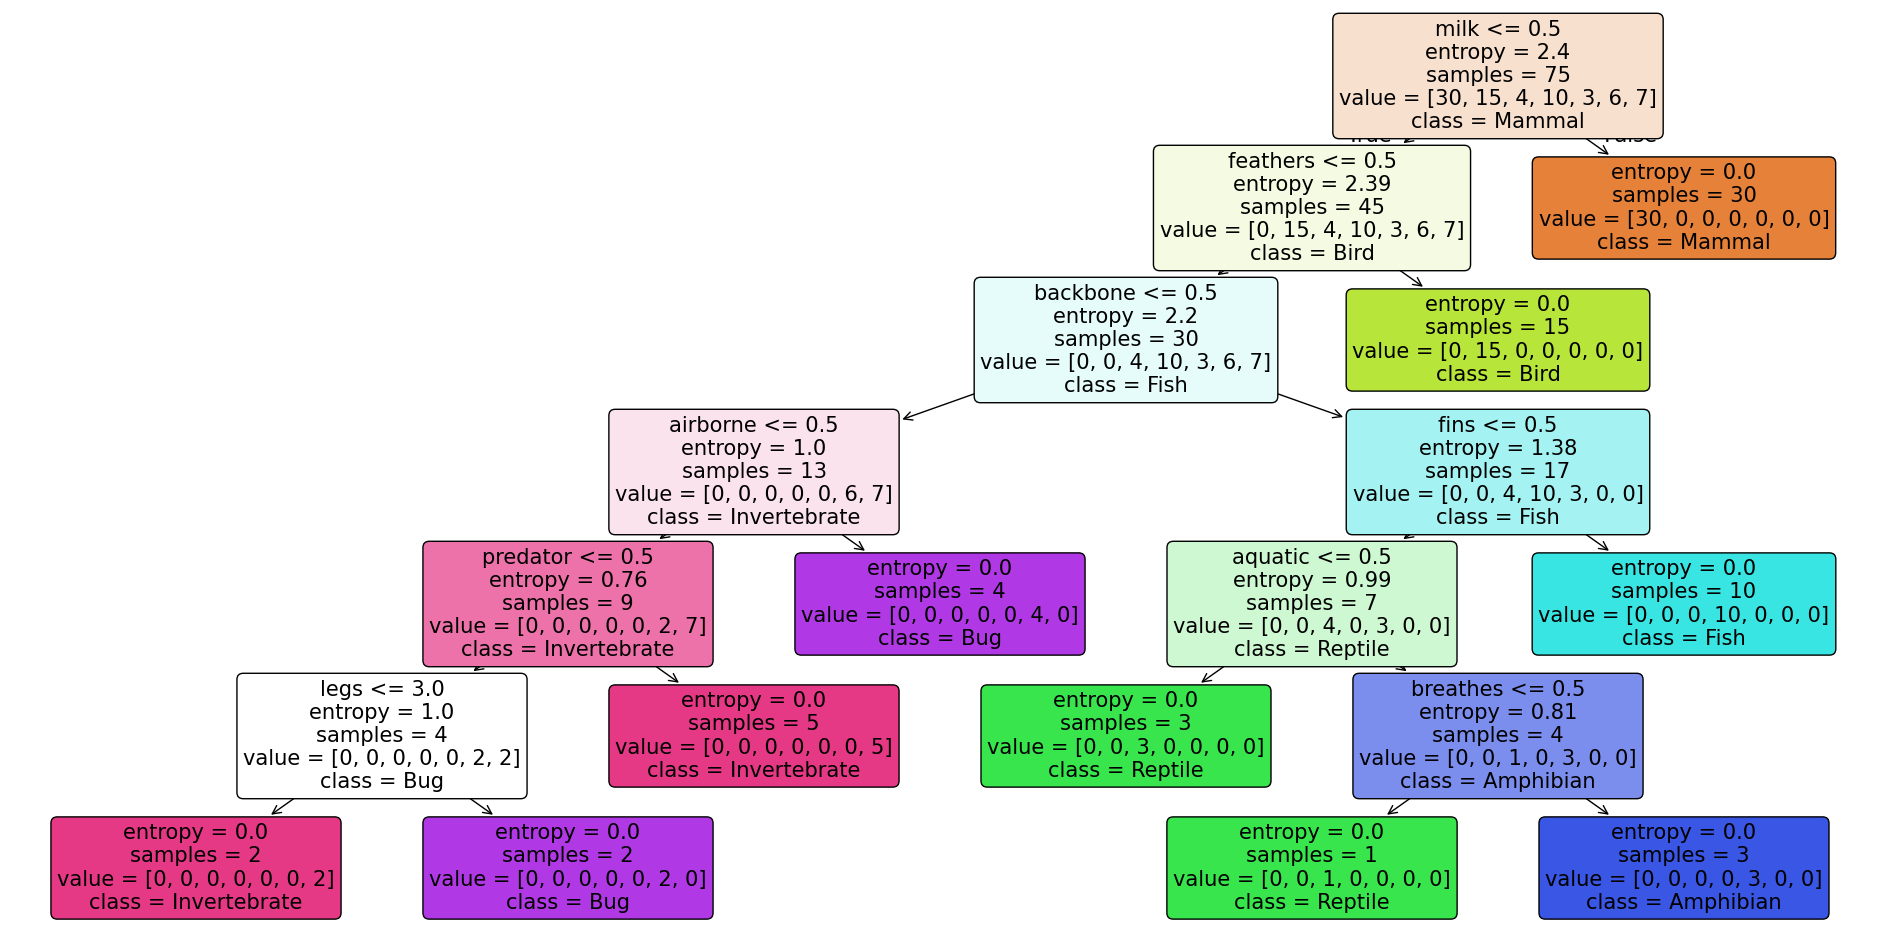

In [15]:
# Visualize the tree (sklearn's plot_tree: no graphviz / pydotplus install needed)
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(24, 12))
plot_tree(tree, filled=True, rounded=True,
          feature_names=feature_names, class_names=class_names,
          proportion=False, precision=2)
plt.show()

## 7. Prune the tree

In [16]:
# max_depth=4 is PRE-pruning: growth is stopped early. (Post-pruning would use ccp_alpha.)
tree_prune = DecisionTreeClassifier(criterion = 'entropy', max_depth = 4, random_state=42)
tree_prune.fit(X_train, y_train)
y_pruned = tree_prune.predict(X_test)   # predict with the PRUNED tree

In [17]:
print(accuracy_score(y_test, y_pruned) * 100 , "%")

96.15384615384616 %


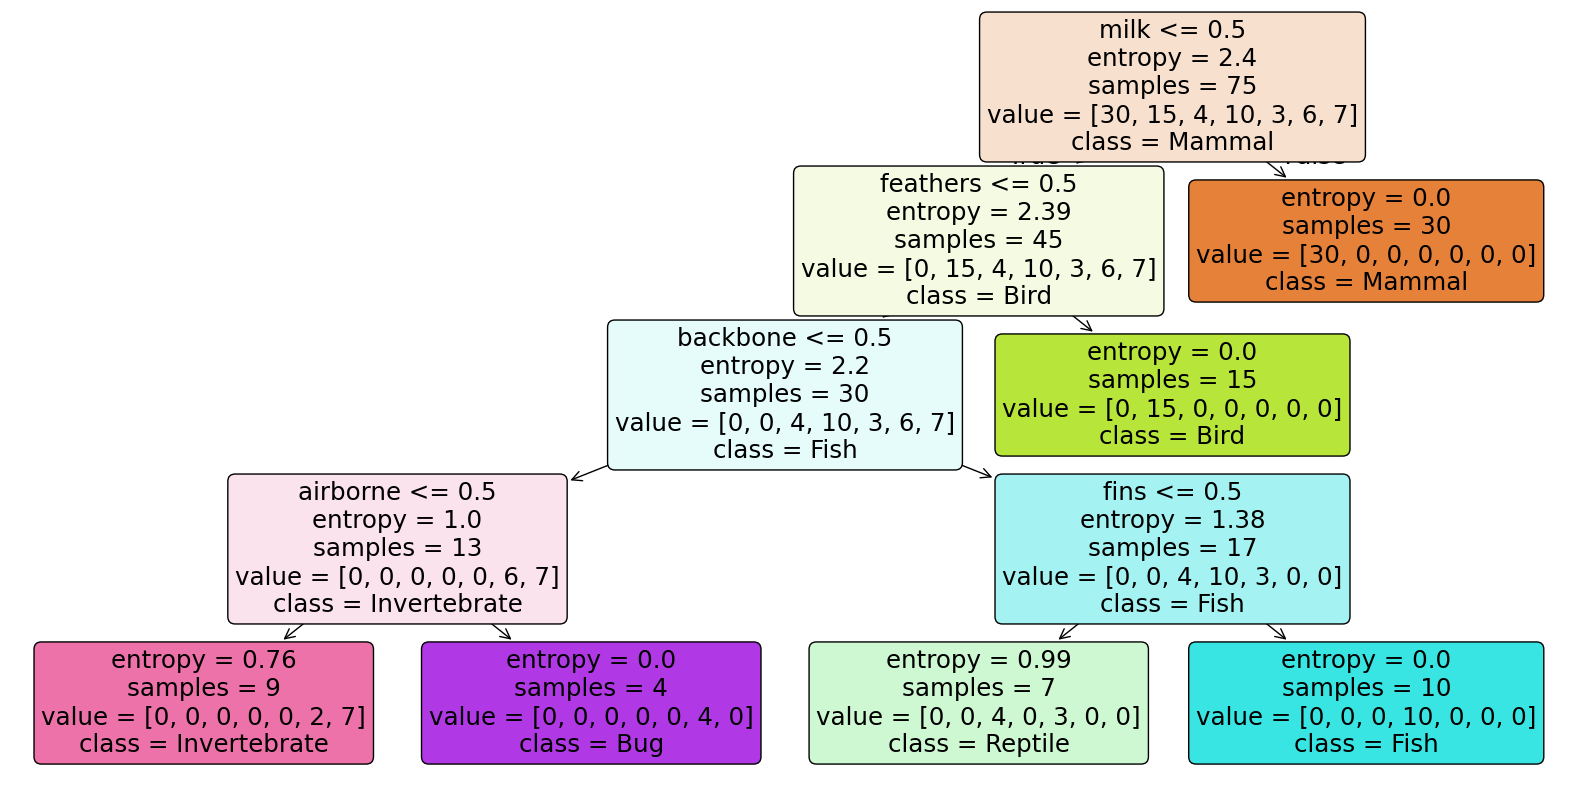

In [18]:
plt.figure(figsize=(20, 10))
plot_tree(tree_prune, filled=True, rounded=True,
          feature_names=feature_names, class_names=class_names,
          proportion=False, precision=2)
plt.show()